# Defensive Value

The **defensive index** averages three families of z-scores, each computed within position group (G = PG + SG, F = SF + PF, C):

| Family | Components |
|---|---|
| Box score | Steals, blocks and defensive rebounds per 100 possessions; charges drawn per 36 minutes |
| Advanced | DBPM, defensive win shares per 48 minutes, defensive rating (negated) |
| On/off | Team defensive rating with the player on the court minus off (negated), minutes-weighted across teams for traded players |

The **offense score** averages z-scores of OBPM and TS% relative to the position group. **Hidden defenders** have a below-average offense score and top-quartile minutes per game for their group. **Rookie scale** = within the first four NBA seasons.

Qualifiers: at least 20 games and 500 minutes. Hover a dot for the player's components.

Source: Basketball-Reference (per 100 possessions, advanced, play-by-play, team on/off).

In [1]:
import pandas as pd
import plotly.io as pio

from nba_analytics.config import season_label
from nba_analytics.players.defense import defense_frame, hidden_defenders, top_defenders
from nba_analytics.players.defense_plots import plot_offense_defense

# Interactive in JupyterLab / VS Code; static PNG fallback where Plotly can't run (e.g. GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 0.7
pd.set_option("display.max_rows", 100)

SEASONS = [2023, 2024, 2025, 2026]
frames = {s: defense_frame(s) for s in SEASONS}

In [2]:
pd.DataFrame({season_label(s): {
    "Qualifiers": len(df),
    "Hidden defenders": int(df["hidden_defender"].sum()),
    "  of which rookie scale": int((df["hidden_defender"] & df["rookie_scale"]).sum()),
} for s, df in frames.items()})

,2022-23,2023-24,2024-25,2025-26
Qualifiers,367,359,373,377
Hidden defenders,15,15,24,18
of which rookie scale,8,5,10,9


## 2025-26

### Offense vs. defense

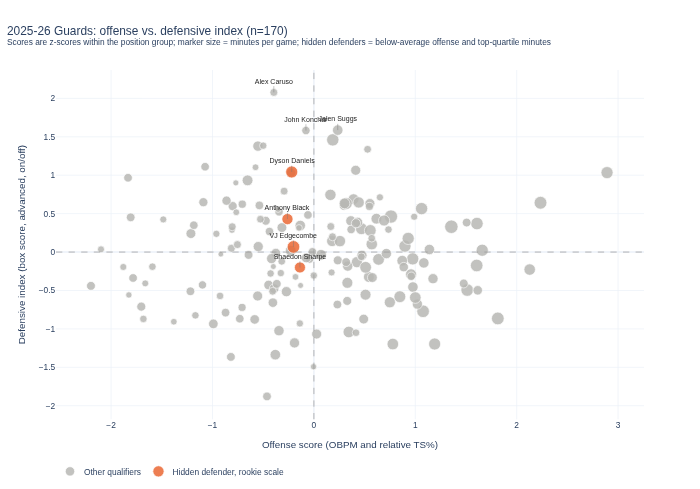

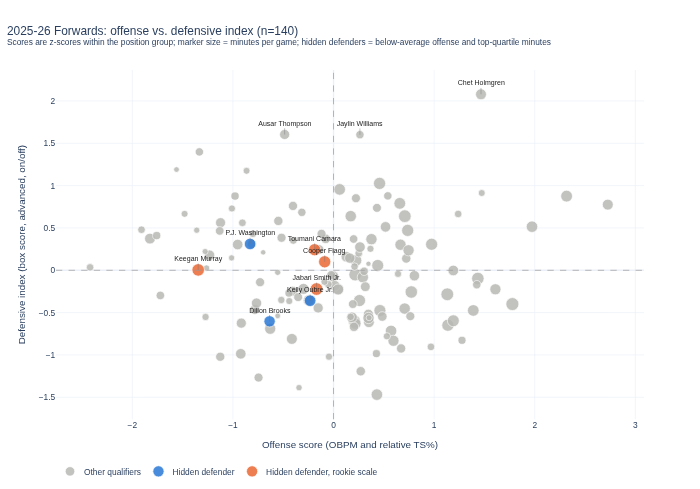

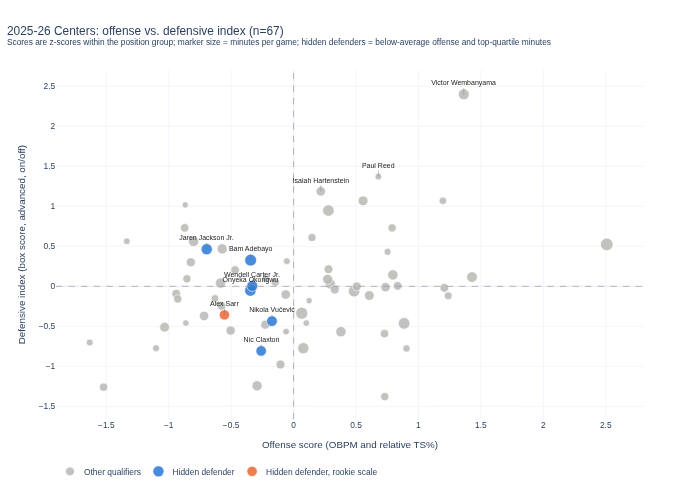

In [3]:
for group in ['G', 'F', 'C']:
    plot_offense_defense(frames[2026], group).show()

### Top 15 defensive index by group

In [4]:
top_defenders(frames[2026], 'G')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
272,Alex Caruso,OKC,SG,31.0,9,18.2,2.08,100.00,1.29,2.86,2.08,-7.60,-0.40,False
149,Jalen Suggs,ORL,PG,24.0,5,27.6,1.59,99.41,1.33,1.57,1.86,-6.80,0.24,False
259,John Konchar,UTA,SG,29.0,7,19.9,1.58,98.82,1.62,0.90,2.22,-8.11,-0.08,False
9,Derrick White,BOS,SG,31.0,9,34.1,1.46,98.24,1.12,1.04,2.22,-8.10,0.19,False
252,Dru Smith,MIA,SG,28.0,4,16.3,1.38,97.65,1.32,2.22,0.61,-2.30,-0.50,True
70,Cason Wallace,OKC,SG,22.0,3,26.6,1.38,97.06,0.38,2.70,1.06,-3.90,-0.55,True
176,Javonte Green,DET,SG,32.0,7,17.6,1.34,96.47,0.94,2.24,0.83,-3.10,0.53,False
322,Vince Williams Jr.,UTA,SG,25.0,4,20.5,1.11,95.88,0.78,-0.15,2.70,-9.84,-1.07,True
353,Jamaree Bouyea,PHO,PG,26.0,4,14.0,1.10,95.29,0.54,0.91,1.86,-6.80,-0.58,True
169,Ajay Mitchell,OKC,SG,23.0,2,25.8,1.06,94.71,0.49,1.87,0.83,-3.10,0.41,True


In [5]:
top_defenders(frames[2026], 'F')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
78,Chet Holmgren,OKC,PF,23.0,3,28.9,2.08,100.00,1.33,2.70,2.21,-7.1,1.47,True
97,Ausar Thompson,DET,SF,23.0,3,26.0,1.60,99.29,1.48,2.96,0.37,-1.0,-0.49,True
219,Jaylin Williams,OKC,PF,23.0,4,19.6,1.60,98.57,1.26,2.75,0.79,-2.4,0.26,True
154,Ron Holland,DET,SF,20.0,2,19.9,1.40,97.86,1.22,1.82,1.15,-3.6,-1.33,True
374,Jonathan Isaac,ORL,PF,28.0,9,10.0,1.19,97.14,1.02,1.27,1.27,-4.0,-1.56,False
263,Hugo González,BOS,SF,19.0,1,14.6,1.18,96.43,0.93,1.38,1.21,-3.8,-0.86,True
6,Scottie Barnes,TOR,PF,24.0,5,33.5,1.03,95.71,0.98,1.76,0.34,-0.9,0.46,False
357,Anthony Davis,DAL,PF,32.0,14,31.3,0.96,95.00,1.41,1.20,0.25,-0.6,0.06,False
296,Karlo Matković,NOP,PF,24.0,2,14.7,0.91,94.29,0.72,0.05,1.97,-6.3,1.47,True
340,Grant Williams,CHO,PF,27.0,7,19.8,0.88,93.57,0.13,0.51,2.00,-6.4,0.54,False


In [6]:
top_defenders(frames[2026], 'C')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
102,Victor Wembanyama,SAS,C,22.0,3,29.2,2.40,100.00,1.97,2.97,2.26,-9.70,1.36,True
302,Paul Reed,DET,C,26.0,6,13.9,1.37,98.51,1.31,2.12,0.68,-3.40,0.68,False
253,Isaiah Hartenstein,OKC,C,27.0,8,24.2,1.19,97.01,0.52,2.38,0.66,-3.30,0.22,False
275,Robert Williams,POR,C,28.0,8,17.1,1.07,95.52,0.68,1.49,1.03,-4.80,1.20,False
90,Neemias Queta,BOS,C,26.0,5,25.3,1.07,94.03,0.10,1.22,1.88,-8.20,0.56,False
293,Clint Capela,HOU,C,31.0,12,12.3,1.02,92.54,0.38,0.89,1.78,-7.80,-0.87,False
26,Rudy Gobert,MIN,C,33.0,13,31.3,0.95,91.04,0.09,0.62,2.13,-9.20,0.28,False
300,Dylan Cardwell,SAC,C,24.0,1,20.6,0.73,89.55,0.64,-0.44,1.98,-8.60,-0.87,True
240,Mitchell Robinson,NYK,C,27.0,8,19.6,0.73,88.06,0.78,1.43,-0.01,-0.60,0.79,False
244,Day'Ron Sharpe,BRK,C,24.0,5,18.7,0.61,86.57,0.52,0.05,1.26,-5.70,0.15,False


### Hidden defenders

In [7]:
hidden_defenders(frames[2026])

,Group,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
28,C,Bam Adebayo,MIA,C,28.0,9,32.4,0.33,76.12,-0.09,0.29,0.78,-3.80,-0.34,False
35,C,Onyeka Okongwu,ATL,C,25.0,6,31.0,-0.05,47.76,-0.25,0.26,-0.16,0.00,-0.35,False
175,C,Jaren Jackson Jr.,UTA,C,26.0,8,30.3,0.46,79.10,0.03,-0.61,1.98,-8.57,-0.70,False
37,C,Wendell Carter Jr.,ORL,C,26.0,8,29.3,0.01,56.72,-0.40,-0.14,0.56,-2.90,-0.33,False
110,C,Nikola Vučević,BOS,C,35.0,15,28.4,-0.43,28.36,-0.62,-0.54,-0.15,-0.08,-0.17,False
91,C,Nic Claxton,BRK,C,26.0,7,27.8,-0.81,7.46,-0.21,-0.75,-1.46,5.20,-0.26,False
214,C,Alex Sarr,WAS,C,20.0,2,27.2,-0.36,31.34,-0.02,-1.09,0.04,-0.80,-0.55,True
4,F,Jabari Smith Jr.,HOU,PF,22.0,4,35.1,-0.22,39.29,-0.12,0.32,-0.87,3.10,-0.17,True
327,F,Keegan Murray,SAC,PF,25.0,4,34.5,0.00,52.86,0.24,-1.08,0.85,-2.60,-1.34,True
29,F,Cooper Flagg,DAL,SF,19.0,1,33.5,0.10,57.14,0.12,0.29,-0.11,0.60,-0.09,True


## 2024-25

### Offense vs. defense

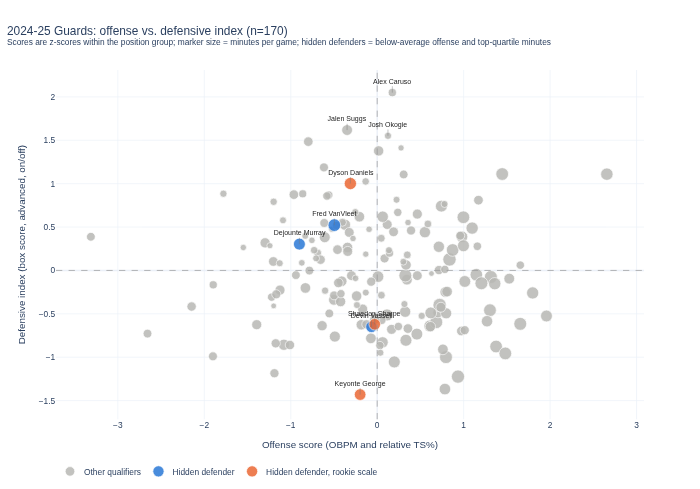

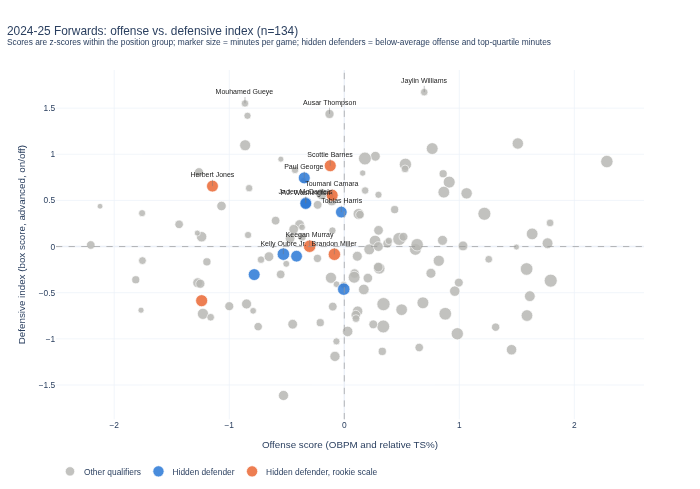

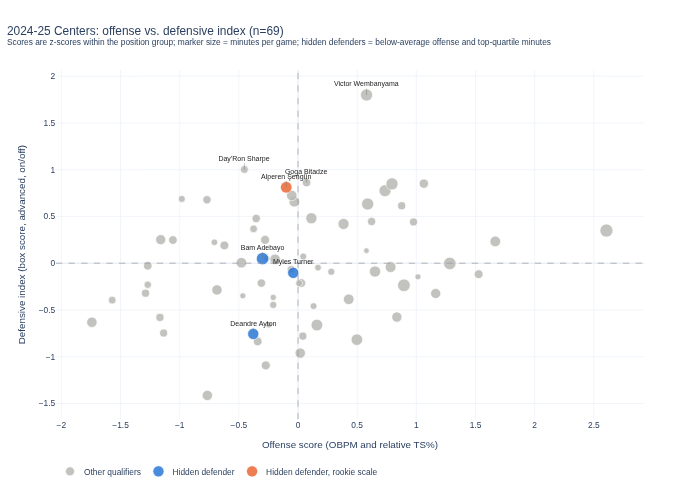

In [8]:
for group in ['G', 'F', 'C']:
    plot_offense_defense(frames[2025], group).show()

### Top 15 defensive index by group

In [9]:
top_defenders(frames[2025], 'G')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
265,Alex Caruso,OKC,SG,30.0,8,19.3,2.05,100.00,1.97,3.16,1.02,-3.30,0.17,False
268,Jalen Suggs,ORL,PG,23.0,4,28.6,1.62,99.41,1.70,1.80,1.35,-4.50,-0.35,True
341,Josh Okogie,CHO,SG,26.0,7,15.6,1.55,98.82,1.69,0.92,2.04,-6.96,0.12,False
130,Kris Dunn,LAC,PG,30.0,9,24.1,1.48,98.24,0.71,2.36,1.38,-4.60,-0.80,False
357,John Konchar,MEM,SG,28.0,6,12.1,1.41,97.65,1.27,1.75,1.21,-4.00,0.28,False
142,Brandin Podziemski,GSW,SG,21.0,2,26.8,1.38,97.06,0.92,0.96,2.25,-7.70,0.02,True
312,Lonzo Ball,CHI,PG,27.0,8,22.2,1.19,96.47,0.59,0.97,2.00,-6.80,-0.62,False
131,Luka Dončić,LAL,PG,25.0,7,35.4,1.11,95.88,1.25,1.08,1.00,-3.24,1.45,False
17,Shai Gilgeous-Alexander,OKC,PG,26.0,7,34.2,1.11,95.29,0.76,2.27,0.29,-0.70,2.66,False
148,Scotty Pippen Jr.,MEM,PG,24.0,3,21.3,1.11,94.71,1.16,1.25,0.91,-2.90,0.31,True


In [10]:
top_defenders(frames[2025], 'F')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
308,Jaylin Williams,OKC,PF,22.0,3,16.7,1.67,100.00,1.73,2.69,0.60,-2.40,0.69,True
362,Mouhamed Gueye,ATL,PF,22.0,2,16.2,1.55,99.25,1.32,1.05,2.29,-8.30,-0.86,True
209,Ausar Thompson,DET,SF,22.0,2,22.5,1.44,98.51,1.57,2.00,0.74,-2.90,-0.13,True
255,Jonathan Isaac,ORL,PF,27.0,8,15.4,1.42,97.76,1.73,2.61,-0.08,0.00,-0.84,False
62,Evan Mobley,CLE,PF,23.0,4,30.5,1.12,97.01,0.95,1.66,0.74,-2.90,1.51,True
91,Draymond Green,GSW,PF,34.0,13,29.2,1.10,96.27,1.10,1.93,0.26,-1.20,-0.86,False
56,Amen Thompson,HOU,SF,22.0,2,32.2,1.06,95.52,0.71,1.99,0.49,-2.00,0.76,True
189,Tari Eason,HOU,PF,23.0,3,24.9,0.98,94.78,1.00,2.39,-0.46,1.30,0.27,True
215,Jalen Johnson,ATL,SF,23.0,4,35.7,0.95,94.03,0.75,0.80,1.31,-4.90,0.18,True
351,Jae'Sean Tate,HOU,SF,29.0,5,11.3,0.95,93.28,0.75,1.06,1.03,-3.90,-0.55,False


In [11]:
top_defenders(frames[2025], 'C')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
171,Victor Wembanyama,SAS,C,21.0,2,33.2,1.80,100.00,1.68,1.53,2.19,-7.80,0.58,True
284,Day'Ron Sharpe,BRK,C,23.0,4,18.2,1.00,98.55,0.47,0.32,2.22,-7.90,-0.45,True
187,Goga Bitadze,ORL,C,25.0,6,20.4,0.86,97.10,0.47,2.01,0.11,-0.90,0.07,False
298,Dereck Lively II,DAL,C,20.0,2,23.1,0.85,95.65,-0.18,0.27,2.46,-8.70,1.06,True
35,Rudy Gobert,MIN,C,32.0,12,33.2,0.85,94.20,0.32,0.76,1.47,-5.40,0.79,False
34,Alperen Şengün,HOU,C,22.0,4,31.5,0.81,92.75,0.30,1.09,1.05,-4.00,-0.10,True
12,Ivica Zubac,LAC,C,27.0,9,32.8,0.78,91.30,-0.17,0.79,1.71,-6.20,0.74,False
290,Chet Holmgren,OKC,C,22.0,2,27.4,0.72,89.86,0.43,2.05,-0.31,0.50,-0.05,True
246,Kevon Looney,GSW,C,28.0,10,15.0,0.69,88.41,0.35,1.00,0.71,-2.90,-0.98,False
210,Donovan Clingan,POR,C,20.0,1,19.8,0.68,86.96,0.27,0.78,0.99,-3.80,-0.77,True


### Hidden defenders

In [12]:
hidden_defenders(frames[2025])

,Group,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
11,C,Bam Adebayo,MIA,C,27.0,8,34.3,0.05,57.97,-0.14,0.41,-0.13,-0.1,-0.30,False
34,C,Alperen Şengün,HOU,C,22.0,4,31.5,0.81,92.75,0.30,1.09,1.05,-4.0,-0.10,True
61,C,Myles Turner,IND,C,28.0,10,30.2,-0.10,43.48,-0.30,-0.12,0.11,-0.9,-0.04,False
235,C,Deandre Ayton,POR,C,26.0,7,30.2,-0.76,10.14,-0.27,-0.39,-1.60,4.8,-0.38,False
78,F,Kelly Oubre Jr.,PHI,SF,29.0,10,34.6,-0.08,47.01,0.36,-0.69,0.09,-0.6,-0.53,False
15,F,Keegan Murray,SAC,PF,24.0,3,34.3,0.00,50.75,-0.06,-0.56,0.63,-2.5,-0.30,True
66,F,Jaylen Brown,BOS,SF,28.0,9,34.3,-0.46,25.37,-0.23,0.42,-1.57,5.2,-0.00,False
279,F,Brandon Miller,CHO,SF,22.0,2,34.2,-0.08,46.27,-0.20,-0.60,0.54,-2.2,-0.09,True
98,F,Bilal Coulibaly,WAS,SF,20.0,2,33.0,-0.59,22.39,-0.24,-1.06,-0.46,1.3,-1.24,True
70,F,Scottie Barnes,TOR,PF,23.0,4,32.8,0.88,91.04,0.64,0.82,1.17,-4.4,-0.12,True


## 2023-24

### Offense vs. defense

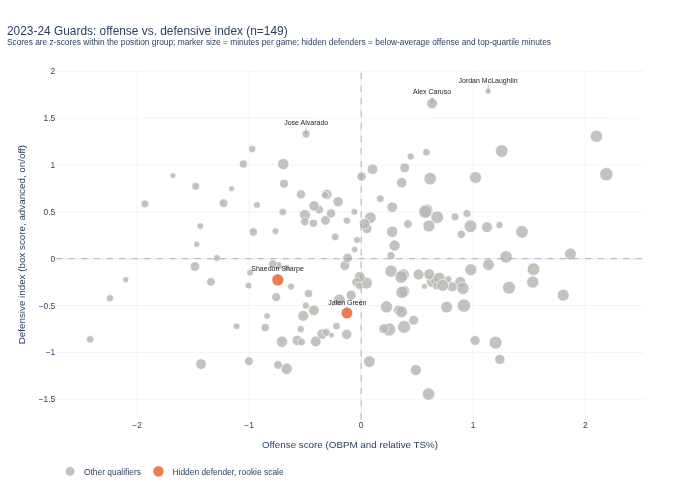

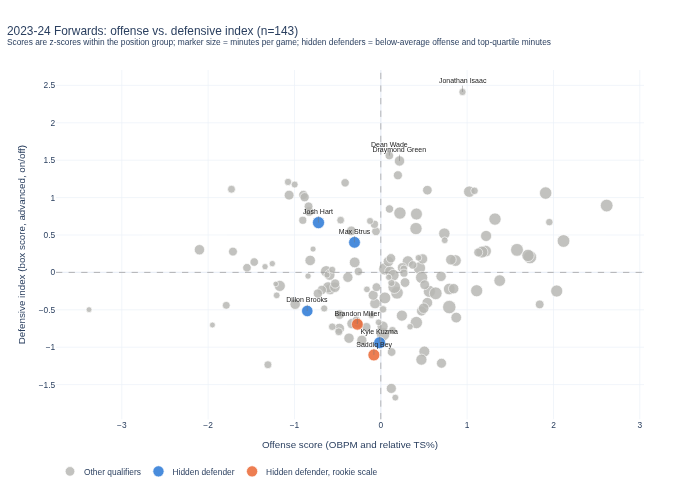

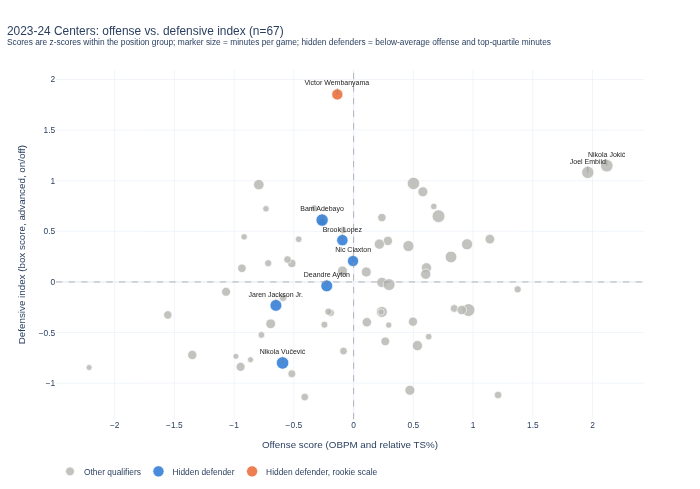

In [13]:
for group in ['G', 'F', 'C']:
    plot_offense_defense(frames[2024], group).show()

### Top 15 defensive index by group

In [14]:
top_defenders(frames[2024], 'G')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
330,Jordan McLaughlin,MIN,PG,27.0,5,11.2,1.79,100.00,0.65,2.39,2.33,-8.00,1.13,False
95,Alex Caruso,CHI,SG,29.0,7,28.7,1.66,99.33,1.71,1.41,1.85,-6.30,0.63,False
258,Jose Alvarado,NOP,PG,25.0,3,18.4,1.33,98.66,0.61,1.45,1.93,-6.60,-0.49,True
27,Shai Gilgeous-Alexander,OKC,PG,25.0,6,34.0,1.31,97.99,1.05,2.03,0.84,-2.70,2.10,False
309,Delon Wright,MIA,PG,31.0,9,15.8,1.17,97.32,0.64,1.32,1.55,-5.24,-0.97,False
113,Donovan Mitchell,CLE,SG,27.0,7,35.3,1.15,96.64,0.44,1.49,1.51,-5.10,1.25,False
272,Keon Ellis,SAC,SG,24.0,2,17.2,1.13,95.97,0.77,1.32,1.31,-4.40,0.58,True
321,Gary Payton II,GSW,SG,31.0,8,15.5,1.09,95.30,0.67,1.43,1.17,-3.90,0.44,False
248,Dennis Smith Jr.,BRK,PG,26.0,7,18.9,1.01,94.63,0.55,1.14,1.34,-4.50,-1.05,False
335,Marcus Smart,MEM,PG,29.0,10,30.3,1.01,93.96,0.71,0.92,1.40,-4.70,-0.69,False


In [15]:
top_defenders(frames[2024], 'F')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
279,Jonathan Isaac,ORL,PF,26.0,7,15.8,2.41,100.00,2.02,2.97,2.25,-8.80,0.95,False
241,Dean Wade,CLE,PF,27.0,5,20.5,1.56,99.30,0.66,1.43,2.60,-10.20,0.10,False
186,Draymond Green,GSW,PF,33.0,12,27.1,1.49,98.60,1.53,1.72,1.22,-4.70,0.22,False
202,Amen Thompson,HOU,SF,21.0,1,22.4,1.30,97.90,1.24,1.91,0.75,-2.80,0.20,True
256,Jae'Sean Tate,HOU,SF,28.0,4,15.9,1.21,97.20,0.53,0.98,2.12,-8.30,-1.07,True
339,Jarred Vanderbilt,LAL,PF,24.0,6,20.0,1.20,96.50,1.33,1.12,1.15,-4.40,-0.41,False
347,Lamar Stevens,MEM,PF,26.0,4,14.7,1.17,95.80,0.73,0.85,1.94,-7.59,-1.00,True
273,Xavier Tillman Sr.,BOS,PF,25.0,4,18.0,1.11,95.10,0.90,1.74,0.70,-2.63,-1.73,True
109,Naz Reid,MIN,PF,24.0,5,24.2,1.10,94.41,0.47,2.05,0.77,-2.90,0.54,False
277,Kevin Love,MIA,PF,35.0,16,16.8,1.09,93.71,1.08,1.64,0.55,-2.00,1.09,False


In [16]:
top_defenders(frames[2024], 'C')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
81,Victor Wembanyama,SAS,C,20.0,1,29.7,1.85,100.00,1.71,2.01,1.85,-5.8,-0.14,True
8,Nikola Jokić,DEN,C,28.0,9,34.6,1.15,98.51,0.32,1.87,1.25,-4.0,2.12,False
210,Joel Embiid,PHI,C,29.0,8,33.6,1.08,97.01,0.36,1.37,1.52,-4.8,1.96,False
21,Rudy Gobert,MIN,C,31.0,11,34.1,0.97,95.52,0.45,1.88,0.59,-2.0,0.50,False
85,Jusuf Nurkić,PHO,C,29.0,10,27.3,0.96,94.03,0.45,1.25,1.19,-3.8,-0.79,False
123,Isaiah Hartenstein,NYK,C,25.0,6,25.3,0.89,92.54,0.36,1.46,0.86,-2.8,0.58,False
304,Isaiah Jackson,IND,C,22.0,3,13.1,0.75,91.04,0.64,0.31,1.28,-4.1,0.67,True
278,Day'Ron Sharpe,BRK,C,22.0,3,15.1,0.73,89.55,0.09,0.02,2.08,-6.5,-0.33,True
282,Jaylin Williams,OKC,C,21.0,2,13.0,0.72,88.06,0.94,0.86,0.36,-1.3,-0.73,True
11,Anthony Davis,LAL,C,30.0,12,35.5,0.65,86.57,0.46,0.96,0.53,-1.8,0.71,False


### Hidden defenders

In [17]:
hidden_defenders(frames[2024])

,Group,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
19,C,Nikola Vučević,CHI,C,33.0,13,34.3,-0.80,10.45,-0.47,-0.87,-1.06,3.0,-0.59,False
38,C,Bam Adebayo,MIA,C,26.0,7,34.0,0.61,83.58,0.08,1.00,0.76,-2.5,-0.26,False
142,C,Deandre Ayton,POR,C,25.0,6,32.4,-0.04,49.25,-0.10,-0.55,0.53,-1.8,-0.22,False
76,C,Jaren Jackson Jr.,MEM,C,24.0,6,32.2,-0.23,43.28,0.45,-0.16,-0.99,2.8,-0.65,False
40,C,Brook Lopez,MIL,C,35.0,16,30.5,0.41,74.63,-0.46,-0.28,1.98,-6.2,-0.09,False
78,C,Nic Claxton,BRK,C,24.0,5,29.8,0.21,64.18,0.47,0.51,-0.37,0.9,-0.00,False
81,C,Victor Wembanyama,SAS,C,20.0,1,29.7,1.85,100.00,1.71,2.01,1.85,-5.8,-0.14,True
10,F,Josh Hart,NYK,SF,28.0,7,33.4,0.67,81.82,0.04,1.01,0.95,-3.6,-0.72,False
91,F,Saddiq Bey,ATL,SF,24.0,4,32.7,-1.10,4.20,-0.74,-1.69,-0.88,3.7,-0.08,True
56,F,Kyle Kuzma,WAS,PF,28.0,7,32.6,-0.94,6.29,-0.22,-1.34,-1.26,5.2,-0.01,False


## 2022-23

### Offense vs. defense

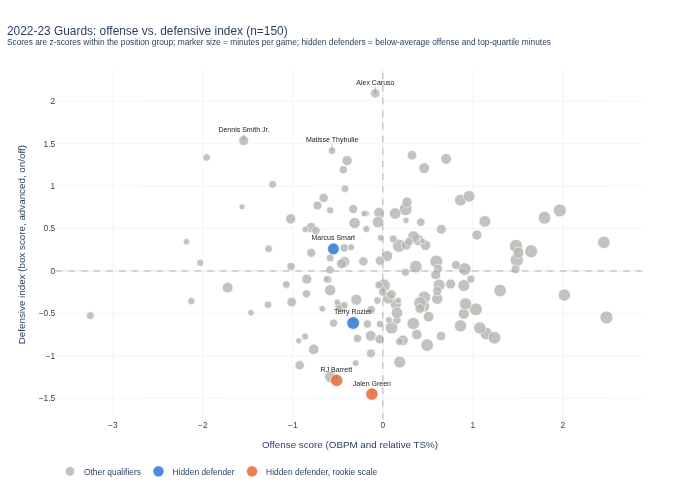

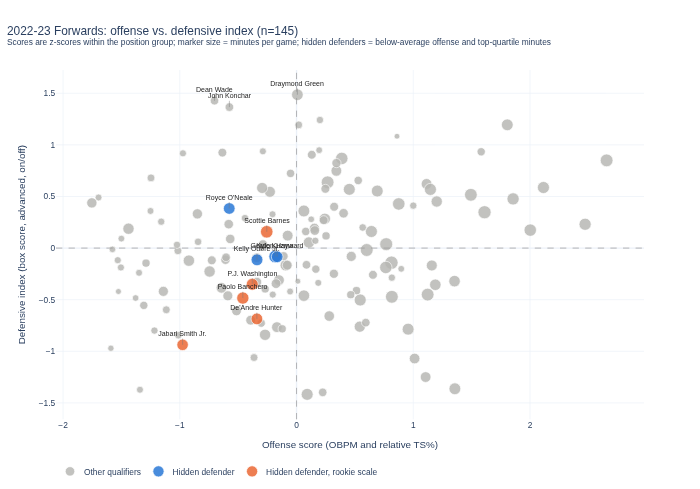

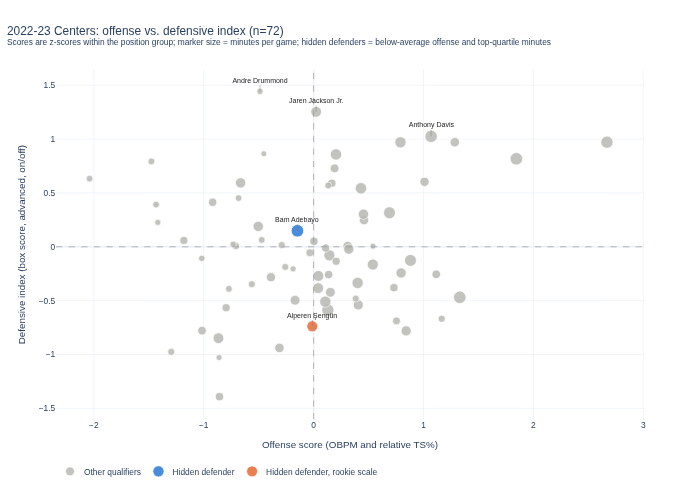

In [18]:
for group in ['G', 'F', 'C']:
    plot_offense_defense(frames[2023], group).show()

### Top 15 defensive index by group

In [19]:
top_defenders(frames[2023], 'G')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
173,Alex Caruso,CHI,PG,28.0,6,23.5,2.09,100.00,2.01,2.70,1.58,-5.70,-0.08,False
203,Dennis Smith Jr.,CHO,PG,25.0,6,25.7,1.54,99.33,0.56,0.89,3.15,-11.50,-1.55,False
229,Matisse Thybulle,POR,SG,25.0,4,16.9,1.42,98.67,1.28,1.49,1.48,-5.37,-0.57,True
224,Delon Wright,WAS,PG,30.0,8,24.4,1.36,98.00,1.18,1.93,0.98,-3.50,0.32,False
356,Ricky Rubio,CLE,PG,32.0,12,17.2,1.34,97.33,0.90,1.86,1.25,-4.50,-1.96,False
48,Derrick White,BOS,SG,28.0,6,28.3,1.32,96.67,1.10,1.42,1.44,-5.20,0.70,False
250,Ben Simmons,BRK,PG,26.0,6,26.3,1.30,96.00,1.73,2.25,-0.08,0.40,-0.40,False
44,Immanuel Quickley,NYK,SG,23.0,3,28.9,1.21,95.33,-0.17,0.43,3.37,-12.30,0.46,True
205,Josh Okogie,PHO,SG,24.0,5,18.8,1.19,94.67,1.37,0.98,1.22,-4.40,-0.44,False
260,Dyson Daniels,NOP,PG,19.0,1,17.7,1.02,94.00,0.43,1.52,1.11,-4.00,-1.23,True


In [20]:
top_defenders(frames[2023], 'F')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
51,Draymond Green,GSW,PF,32.0,11,31.5,1.49,100.00,0.81,1.54,2.11,-7.30,0.01,False
286,Dean Wade,CLE,PF,26.0,4,20.3,1.43,99.31,0.45,1.81,2.02,-7.00,-0.70,True
190,John Konchar,MEM,SF,26.0,4,20.8,1.37,98.62,0.84,2.11,1.15,-3.90,-0.58,True
317,Robert Covington,LAC,PF,32.0,10,16.2,1.24,97.93,1.36,1.78,0.58,-1.90,0.20,False
100,Giannis Antetokounmpo,MIL,PF,28.0,10,32.1,1.19,97.24,0.85,2.47,0.27,-0.80,1.81,False
263,Hamidou Diallo,DET,SF,24.0,5,17.8,1.19,96.55,0.92,-0.02,2.68,-9.30,0.02,False
334,Chimezie Metu,SAC,PF,25.0,5,10.4,1.08,95.86,0.70,0.49,2.05,-7.10,0.86,False
285,Derrick Jones Jr.,CHI,PF,25.0,7,14.0,0.95,95.17,0.45,0.97,1.43,-4.90,0.19,False
258,Jalen Johnson,ATL,SF,21.0,2,14.9,0.94,94.48,0.90,0.99,0.92,-3.10,-0.29,True
252,Brandon Clarke,MEM,PF,26.0,4,19.5,0.93,93.79,0.62,1.90,0.27,-0.80,1.58,True


In [21]:
top_defenders(frames[2023], 'C')

,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
293,Andre Drummond,CHI,C,29.0,11,12.7,1.44,100.00,1.45,1.90,0.98,-4.2,-0.49,False
146,Jaren Jackson Jr.,MEM,C,23.0,5,28.4,1.25,98.61,0.64,1.95,1.16,-4.9,0.02,False
126,Anthony Davis,LAL,C,29.0,11,34.0,1.03,97.22,0.51,1.20,1.37,-5.7,1.07,False
47,Nikola Jokić,DEN,C,27.0,8,33.7,0.97,95.83,0.46,1.76,0.69,-3.1,2.67,False
299,Robert Williams,BOS,C,25.0,5,23.5,0.97,94.44,0.14,1.69,1.08,-4.6,1.28,False
60,Nic Claxton,BRK,C,23.0,4,29.9,0.97,93.06,0.70,1.34,0.88,-3.8,0.79,True
322,Paul Reed,PHI,C,23.0,3,10.9,0.86,91.67,1.08,1.78,-0.27,0.6,-0.45,True
41,Brook Lopez,MIL,C,34.0,15,30.4,0.86,90.28,-0.35,0.82,2.10,-8.5,0.20,False
53,Joel Embiid,PHI,C,28.0,7,34.6,0.82,88.89,0.26,1.21,0.98,-4.2,1.84,False
289,Bismack Biyombo,PHO,C,30.0,12,14.3,0.79,87.50,0.44,1.50,0.43,-2.1,-1.48,False


### Hidden defenders

In [22]:
hidden_defenders(frames[2023])

,Group,Player,Team,Pos,Age,NBA season #,MPG,Defense index,Group pctile,Box score,Advanced,On/off,DRtg on-off,Offense score,Rookie scale
17,C,Bam Adebayo,MIA,C,25.0,6,34.6,0.15,65.28,-0.06,0.26,0.25,-1.4,-0.15,False
71,C,Alperen Şengün,HOU,C,20.0,2,28.9,-0.74,11.11,0.32,-1.14,-1.39,4.9,-0.01,True
63,F,Kyle Kuzma,WAS,PF,27.0,6,35.0,-0.08,48.97,-0.28,-0.77,0.81,-2.7,-0.18,False
11,F,Scottie Barnes,TOR,SF,21.0,2,34.8,0.16,60.00,0.11,0.04,0.33,-1.0,-0.26,True
30,F,Paolo Banchero,ORL,PF,20.0,1,33.8,-0.48,17.93,-0.07,0.02,-1.40,5.1,-0.46,True
39,F,P.J. Washington,CHO,PF,24.0,4,32.6,-0.35,28.28,0.08,-0.22,-0.92,3.4,-0.38,True
179,F,Kelly Oubre Jr.,CHO,SF,27.0,8,32.3,-0.11,45.52,0.48,-0.19,-0.63,2.4,-0.34,False
33,F,Royce O'Neale,BRK,SF,29.0,6,31.7,0.38,74.48,0.17,0.28,0.70,-2.3,-0.58,False
83,F,De'Andre Hunter,ATL,SF,25.0,4,31.7,-0.69,13.79,-0.36,-1.23,-0.46,1.8,-0.34,True
172,F,Gordon Hayward,CHO,SF,32.0,13,31.5,-0.08,48.28,-0.58,-0.65,0.98,-3.3,-0.17,False
